In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.integrate import ode, odeint, solve_ivp, solve_bvp
from scipy import optimize
from matplotlib.cm import ScalarMappable

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})

def runge_kutta_4(f, t, y0, *args, **kwargs):
    """
    Metoda Runge-Kutta 4. reda za reševanje diferencialne enačbe: y' = f(t, y)
    
    :param f: funkcija, ki jo kličemo s parametroma t in y in vrne 
              vrednost prvega odvoda
    :param t: ekvidistanten časovni vektor oz. neodvisna spremenljivka
    :param y0: začetna vrednost
    :param args: dodatni argumenti funkcije f (brezimenski)
    :param kwargs: dodatni argumenti funkcije f (poimenovani)
    :return y: funkcijske vrednosti.
    """
    def RK4(f, t, y, *args, **kwargs):
        k0 = h*f(t, y, *args, **kwargs)
        k1 = h*f(t + h/2.0, y + k0/2.0, *args, **kwargs)
        k2 = h*f(t + h/2.0, y + k1/2.0, *args, **kwargs)
        k3 = h*f(t + h, y + k2, *args, **kwargs)
        return (k0 + 2.0*k1 + 2.0*k2 + k3)/6.0
    
    y = np.zeros(shape=(len(t),len(y0)))
    y[0] = y0
    h = t[1]-t[0]

    for i, ti in enumerate(t[1:]):
        y[i+1] = y[i] + RK4(f, ti, y[i], *args, **kwargs)
        
    return y.T

# test
### linearen vodoravni met

iteracija 1: -5.773159728050814e-15


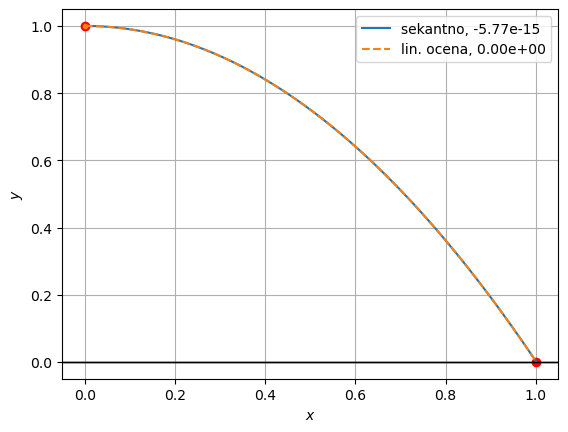

In [2]:
def vodoravni(t,y):
    xx,yy,vx,vy=y
    return np.array([vx,vy,0*vx,-9.81+0*vx])
def napaka_met(vx0):
    y_zp=np.array([0,1,vx0,0])
    y = runge_kutta_4(vodoravni, t, y0=y_zp)
    err = y[0,-1] - x_f
    return err

vx0 = 1. #parameter, guess
vy0 = 0. #zp = 0 vodoravno!
x0,y0=0.,1. #zp zač. lega
x_f, y_f = 1, 0. #lega končna
dt = 0.001
#t_max=0.45 #pravilno določiti!
t_max = (abs(y_f-y0)*2/9.81)**0.5 #glede na višino
t=np.arange(0, t_max, dt)

# METODA 1: iteracijsko, sekantno iskanje ničle
tol=10**(-10)
err=1
vx1 = 2.
i=0
while abs(err) > tol:
    i+=1
    f0 = napaka_met(vx0)
    f1 = napaka_met(vx1)
    vx2 = vx1 - f1*(vx1-vx0)/(f1-f0)
    err = napaka_met(vx2)
    vx0 = vx1
    vx1 = vx2
    print(f'iteracija {i}: {err}')
vx0 = vx2
y = runge_kutta_4(vodoravni, t, y0=np.array([x0,y0,vx0,vy0]))
plt.plot(x_f, y_f,'ro')
plt.plot(x0,y0, 'ro')
plt.axhline(y=0,color='k',linewidth=1)
plt.plot(y[0], y[1],'C0',label=f'sekantno, {err:.2e}')

# METODA 2: za linearne probleme dela super
vx0 = 1
vx1 = 2
y1 = runge_kutta_4(vodoravni, t, np.array([x0,y0,vx0,vy0]))
y2 = runge_kutta_4(vodoravni, t, np.array([x0,y0,vx1,vy0]))
theta = (x_f-y1[0,-1])/(y2[0,-1]-y1[0,-1])
y = (1-theta)*y1+theta*y2
err1 = y[0,-1] - x_f
plt.plot(x0,y0, 'C1.')
plt.axhline(y=0,color='k',linewidth=1)
plt.plot(y[0], y[1], 'C1--',label=f'lin. ocena, {err1:.2e}')
plt.legend()
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid()

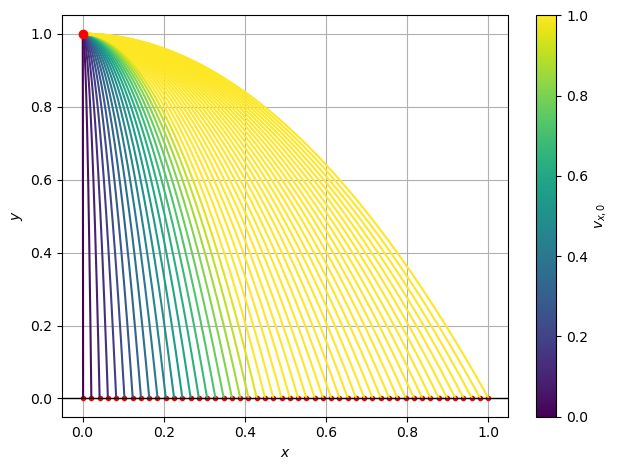

In [3]:
lege = np.linspace(0.001,1,50)
vx0 = 1
vx1 = 2
fig, ax = plt.subplots()
cmap = plt.cm.viridis
for x_f in lege:
    y1 = runge_kutta_4(vodoravni, t, np.array([x0,y0,vx0,vy0]))
    y2 = runge_kutta_4(vodoravni, t, np.array([x0,y0,vx1,vy0]))
    theta = (x_f-y1[0,-1])/(y2[0,-1]-y1[0,-1])
    y = (1-theta)*y1+theta*y2
    err = y[0,-1] - x_f
    ax.plot(x_f,y_f, 'r.')
    ax.plot(y[0], y[1], '-', color=cmap(y[2, 0]))
ax.plot(x0,y0, 'ro')
ax.axhline(y=0,color='k',linewidth=1)
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid()
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('$v_{x,0}$')
plt.tight_layout()
#plt.savefig('./slike/vodoravni.pdf')

### nelin. poševni met

(99.8999999999986, 95.0048050949992)

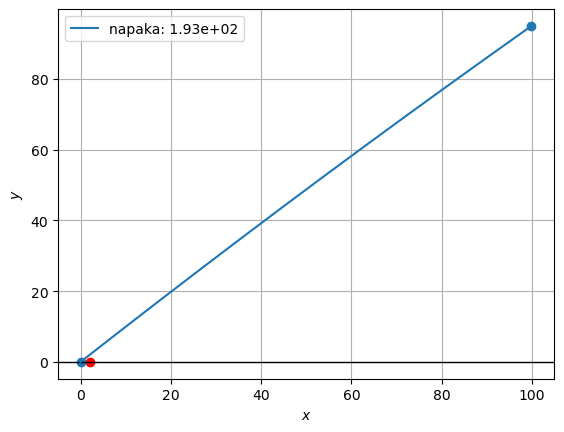

In [4]:
def napaka_met(v0):
    y_zp=np.array([x0,y0,v0[0],v0[1]])
    y = runge_kutta_4(vodoravni, t, y0=y_zp)
    err = y[0:2,-1] - np.array([x_f,y_f])
    return err

vx0 = 100 #parameter, guess
vy0 = 100 #parameter, guess
x0,y0=0,0 #zp zač. lega
x_f,y_f= 2,0 #lega končna
t_max= 1 #določa pot!
#y0=vy0+t_max**2*9.81/2
dt = 0.001
t=np.arange(0, t_max, dt)

res = optimize.root(napaka_met, x0=np.array([vx0,vy0]), tol=10**(-10))
v0x,v0y = res.x
err = napaka_met(np.array([vx0,vy0]))

y = runge_kutta_4(vodoravni, t, y0=np.array([x0,y0,vx0,vy0]))
plt.plot(x_f, y_f,'ro')
plt.plot(x0,y0, 'C0o')
plt.plot(y[0,-1],y[1,-1], 'C0o')
plt.axhline(y=0,color='k',linewidth=1)
plt.plot(y[0], y[1], label=f'napaka: {np.sum(err):.2e}')
plt.legend()
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid()
y[0,-1],y[1,-1]

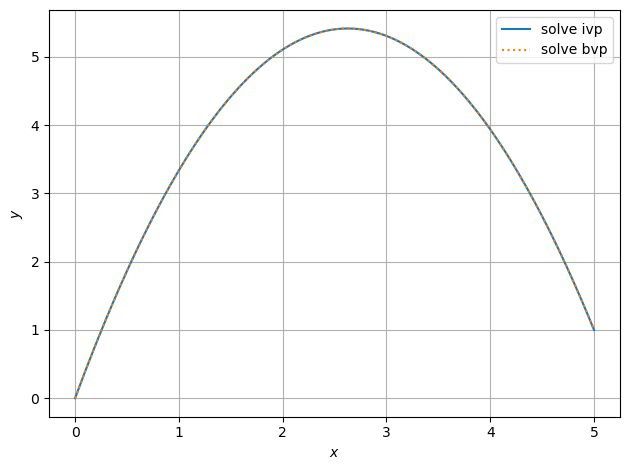

In [5]:
#Slavič
def f_poševno(t, y, g=9.81):
    x, vx, yy, vy = y
    return np.array([vx, 0.*vx, vy, -g+0*vx])
def r_poševno(v0, t):
    sol = solve_ivp(lambda t, y: f_poševno(t, y),
                      t_span=(t[0], t[-1]),
                      y0=[0, v0[0], 0, v0[1]]).y
    r = sol[0:3:2, -1] - ciljna_lega
    return r

ciljna_lega = [5.,1.]
v0 = [1.,1.]
t = np.linspace(0, 2, 100)
rešitev = optimize.root(r_poševno, x0=np.array(v0), args=(t))
sol = solve_ivp(lambda t, y: f_poševno(t, y),
                t_span=(t[0], t[-1]),
                y0=[0, rešitev.x[0], 0, rešitev.x[1]],
                t_eval=t)

def mejni_preostanek(ya, yb):
    return np.array([ya[0], ya[2], yb[0]-ciljna_lega[0], yb[2]-ciljna_lega[1]])

y0 = np.zeros((4, t.size))
y0[1] = v0[0] # hitrost v x smeri
y0[3] = v0[1] # hitrost v y smeri
res = solve_bvp(f_poševno,bc=mejni_preostanek, x=t, y=y0)

plt.plot(res.y[0], res.y[2], label='solve ivp')
plt.plot(sol.y[0], sol.y[2],':',label='solve bvp')
plt.legend()
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid()
plt.tight_layout()
#plt.savefig('./slike/posevni_met.pdf')

# vrv

In [6]:
def vrv(s,y):
    x,y,alpha,F=y
    x_s = np.cos(alpha)
    y_s = np.sin(alpha)
    F_s = np.sin(alpha) - beta*x*np.cos(alpha)
    alpha_s = 1/F * (np.cos(alpha) + beta*x*np.sin(alpha))
    return np.array([x_s,y_s,alpha_s,F_s])
# def napaka_vrv(y, y_ref):
#     x,y,alpha,F=y
#     x_rp,y_rp,alpha_rp,F_rp = y_ref
#     return (x-x_rp)**2+(y-y_rp)**2
def napaka_vrv(y0_opt):
    y_zp=np.array([x0,y0,y0_opt[0],y0_opt[1]])
    y = runge_kutta_4(vrv, s, y_zp)
    #y = solve_ivp(vrv, y0=y_zp, t_span=(0.,L), t_eval=s).y
    err = y[0:2,-1] - np.array([x_f,y_f])
    return np.array([err[0], err[1]])
    #return np.array([0*y[0,-1], 0*y[0,-1], err[0], err[1]])

array([6.12262167e-17, 4.99900000e-01])

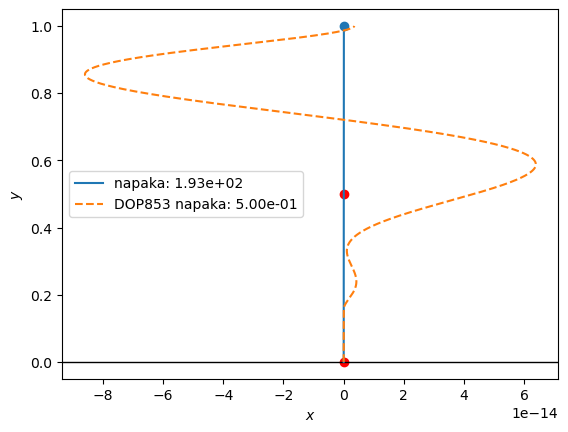

In [7]:
#ROČNI PARAMETRI
#omega = 0.1 #parameter
beta = 100
alpha0 = np.pi/2 #ZP
F0=1. #ZP
x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.5 #RP lega končnega vpetja
ds = 0.0001
L=1 #dolžina vrvi
#rho= 1.
#beta = omega**2*L/9.81 #brezdim.
#F0 = rho*y_f #prosto visi, mala omega
s=np.arange(0., L, ds)
y_zp=np.array([x0,y0,alpha0,F0])

method='DOP853'
res = solve_ivp(vrv,y0=y_zp, t_span=(0.,L), method=method,t_eval=s)
y1 = res.y
s1 = res.t
err1 = np.sum(y1[0:2,-1] - np.array([x_f,y_f]))
y = runge_kutta_4(vrv, s, y0=y_zp)

plt.plot(x_f, y_f,'ro')
plt.plot(x0,y0, 'ro')
plt.plot(y[0,-1],y[1,-1], 'C0o')
plt.axhline(y=0,color='k',linewidth=1)
plt.plot(y[0], y[1], label=f'napaka: {np.sum(err):.2e}')
plt.plot(y1[0], y1[1],'--', label=f'{method} napaka: {err1:.2e}')
plt.legend()
plt.xlabel('$x$')
plt.ylabel('$y$')
napaka_vrv(y[2:,-1])

In [8]:
def vrv_min(beta, alpha0=np.pi/4, F0=1):
    y_zp=np.array([alpha0,F0])
    res = optimize.root(napaka_vrv, x0=y_zp, tol=10**(-10),method='lm')
    alpha0,F0 = res.x
    y = runge_kutta_4(vrv, t=s, y0=np.array([x0,y0,alpha0,F0]))
    return y, (alpha0,F0)

(1.219848381128249, 1.1095740456458865)

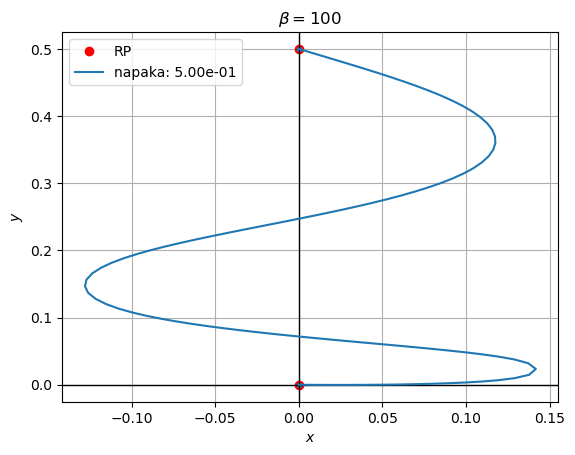

In [9]:
# ISKANJE MINIMUMA
beta = 100 #parameter
alpha0 = np.pi/4*0 #ZP
F0= 1 #ZP
x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.5 #RP lega končnega vpetja
ds = 0.01
L=1 #dolžina vrvi
s=np.arange(0., L, ds)
y_zp=np.array([alpha0,F0])
#F0= 0.5*(L-y_f) #prosto

res = optimize.root(napaka_vrv, x0=y_zp, tol=10**(-6),method='lm')
alpha0,F0 = res.x
# alpha0,F0 = optimize.fsolve(napaka_vrv, x0=np.array([alpha0,F0])) #implementirano v root

# method='DOP853'
# res = solve_ivp(vrv,y0=np.array([x0,y0,alpha0,F0]), t_span=(0.,L), method=method,t_eval=s)
# y1 = res.y
# s1 = res.t
# err1 = np.sum(y1[0:2,-1] - np.array([x_f,y_f]))
y = runge_kutta_4(vrv, t=s, y0=np.array([x0,y0,alpha0,F0]))
#err = napaka_vrv(np.array([x0,y0,alpha0,F0])) #nan?!
err = np.sum(y[0:2,-1] - np.array([x_f,y_f]))

y, (alpha0,F0) = vrv_min(beta, alpha0, F0)
alpha0=-alpha0
err = np.sum(y1[0:2,-1] - np.array([x_f,y_f]))

plt.plot(x_f, y_f,'ro',label='RP')
plt.plot(x0,y0, 'ro')
plt.plot(y[0,0],y[1,0], 'C0.')
plt.plot(y[0,-1],y[1,-1], 'C0.')
plt.axhline(y=0,color='k',linewidth=1)
plt.axvline(x=0,color='k',linewidth=1)
plt.plot(y[0], y[1], '-', label=f'napaka: {err:.2e}')
#plt.plot(y1[0], y1[1],'--', label=f'{method} napaka: {err1:.2e}')
plt.legend()
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid()
plt.title(f'$\\beta=${beta}')
np.rad2deg(alpha0),F0

In [10]:
# solve_bvp
def napaka_vrv_bvp(y_a, y_b):
    return np.array([y_a[0],y_a[1],y_b[0]-x_f,y_b[1]-y_f])

y_guess = np.zeros((4, len(s)))
y_guess[2] = alpha0
y_guess[3] = F0
solve_bvp(vrv, napaka_vrv_bvp, x=s, y=y_guess,max_nodes=1000)

       message: The maximum number of mesh nodes is exceeded.
       success: False
        status: 1
             x: [ 0.000e+00  1.111e-03 ...  9.889e-01  9.900e-01]
           sol: <scipy.interpolate._interpolate.PPoly object at 0x7472cdf86270>
             p: None
             y: [[ 1.473e+08  1.469e+08 ... -3.828e+04  0.000e+00]
                 [-2.248e+07 -2.246e+07 ... -7.730e+04  5.000e-01]
                 [-3.268e+11 -3.264e+11 ... -4.715e+11 -4.715e+11]
                 [-3.458e+35 -3.458e+35 ... -3.458e+35 -3.458e+35]]
            yp: [[ 9.478e-01  8.568e-01 ... -9.997e-01 -1.000e+00]
                 [-3.190e-01 -5.156e-01 ... -2.267e-02 -8.936e-03]
                 [ 1.358e-26  2.190e-26 ... -2.509e-31  2.892e-36]
                 [-1.396e+10 -1.258e+10 ... -3.827e+06 -8.936e-03]]
 rms_residuals: [ 3.684e+11  1.130e+11 ...  3.002e+07  7.737e+07]
         niter: 3

(-1.2535800202589853, 1.1348722860982352, 0.0010099689822157254)

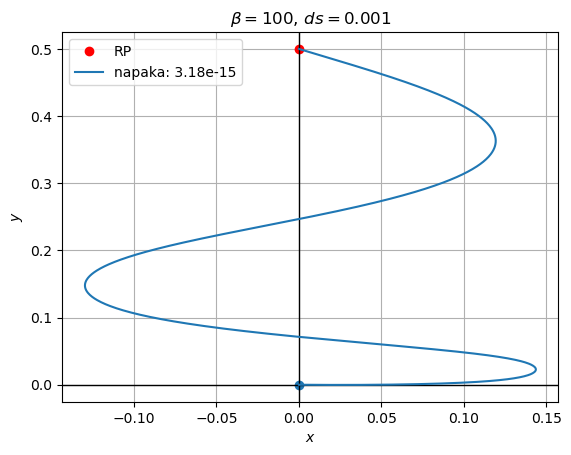

In [11]:
#z funkcijo
x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.5 #RP lega končnega vpetja
ds = 0.001
L=1 #dolžina vrvi
s=np.arange(0., L, ds)

beta = 100 #parameter
alpha0 = np.pi/4 #ZP
F0= 1 #ZP

y, (alpha0,F0) = vrv_min(beta, alpha0, F0)
err = np.sum(y[0:2,-1] - np.array([x_f,y_f]))
L_err = np.abs(1 - np.sum(np.sqrt(np.diff(y[0])**2 + np.diff(y[1])**2)))

plt.plot(x_f, y_f,'ro',label='RP')
plt.plot(x0,y0, 'C0o')
#lt.plot(y[0,0],y[1,0], 'C0o')
#plt.plot(y[0,-1],y[1,-1], 'C0.')
plt.axhline(y=0,color='k',linewidth=1)
plt.axvline(x=0,color='k',linewidth=1)
plt.plot(y[0], y[1], '-', label=f'napaka: {err:.2e}')
#plt.plot(y1[0], y1[1],'--', label=f'{method} napaka: {err1:.2e}')
plt.legend()
plt.grid()
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title(f'$\\beta=${beta}, $ds=${ds}')
np.rad2deg(alpha0), F0, L_err

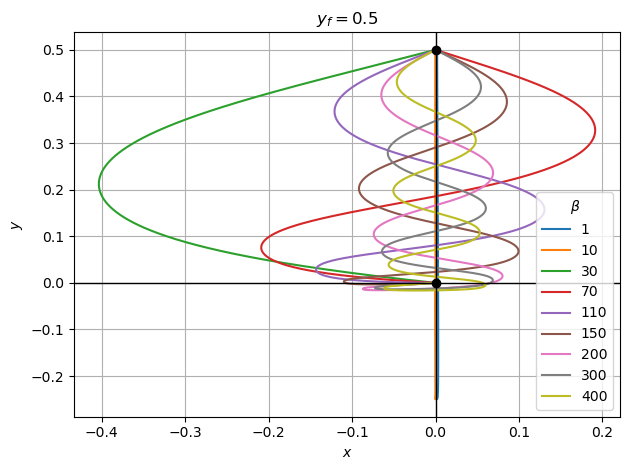

In [28]:
#skupinski prikaz
x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.5 #RP lega končnega vpetja [0.3, 0.9]
ds = 0.001
L=1 #dolžina vrvi
s=np.arange(0., L, ds)
alpha0 = np.pi/4 #ZP
F0= 0.1 #ZP 0.1:za vse ok, 1 le za y_f<0.6

beta_list = [1,10,30,70,110,150,200,300,400]
for beta in beta_list:
    y, (alpha0,F0) = vrv_min(beta, alpha0, F0) #hitreje teče - uporaba prejšnjih ZP!
    plt.plot(y[0], y[1], '-', label=str(int(beta)))

plt.title(f'$y_f=${y_f}')
plt.legend(title='$\\beta$')
plt.grid()
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.plot(x_f, y_f,'ko')
plt.plot(x0,y0, 'ko')
plt.axhline(y=0,color='k',linewidth=1)
plt.axvline(x=0,color='k',linewidth=1)
plt.tight_layout()
#plt.savefig(f'./slike/vrv_yf_{y_f}.pdf')

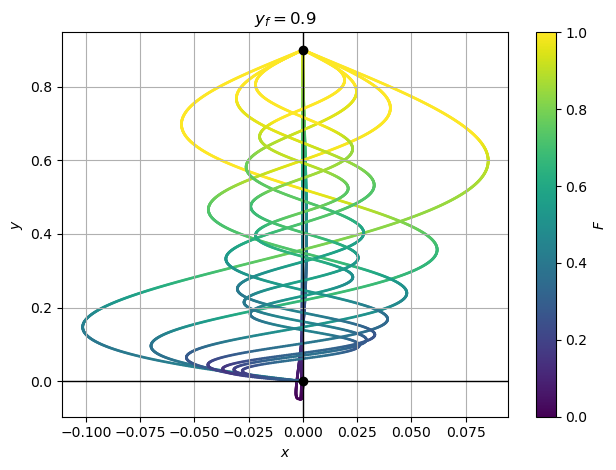

In [48]:
#skupinski prikaz
x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.9 #RP lega končnega vpetja [0.3, 0.9]
ds = 0.001
L=1 #dolžina vrvi
s=np.arange(0., L, ds)
alpha0 = np.pi/4 #ZP
F0= 0.1 #ZP 0.1:za vse ok, 1 le za y_f<0.6

fig, ax = plt.subplots()
cmap = plt.get_cmap('viridis')
beta_list = [1,10,30,70,110,150,200,300,400]
sm=[]
for beta in beta_list:
    y, (alpha0,F0) = vrv_min(beta, alpha0, F0) #hitreje teče - uporaba prejšnjih ZP!
    # y4_min = min(y[3])
    # y4_max = max(y[3])
    # norm = plt.Normalize(vmin=y4_min, vmax=y4_max)
    smi=ax.scatter(y[0], y[1], s=1, label=str(int(beta)), color=cmap((y[3])))
    sm.append(smi)

sm_scalar = ScalarMappable(cmap=cmap)
sm_scalar.set_array([])
cbar = plt.colorbar(sm_scalar,ax=ax,label='$F$')

plt.title(f'$y_f=${y_f}')
#plt.legend(title='$\\beta$')
plt.grid()
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.plot(x_f, y_f,'ko')
plt.plot(x0,y0, 'ko')
plt.axhline(y=0,color='k',linewidth=1)
plt.axvline(x=0,color='k',linewidth=1)
plt.tight_layout()
#plt.savefig(f'./slike/F_vrv_yf_{y_f}.pdf')

## napake

In [13]:
# napaka lege
x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.5 #RP lega končnega vpetja
ds = 0.001
L=1 #dolžina vrvi
s=np.arange(0., L, ds)
alpha0 = np.pi/4 #ZP
F0= 0.1 #ZP

beta_list = np.linspace(1,200,50)
lege = np.arange(0.4, 0.61, 0.1)
napaka = []
for y_f in lege:
    nap=[]
    alpha0,F0 = np.pi/4, 0.1
    for beta in beta_list:
        y, (alpha0,F0) = vrv_min(beta, alpha0, F0) #uporaba predhodnjih ZP
        err = np.sum(y[0:2,-1] - np.array([x_f,y_f]))
        nap.append(err)
    napaka.append(nap)
napaka = np.array(napaka)

KeyboardInterrupt: 

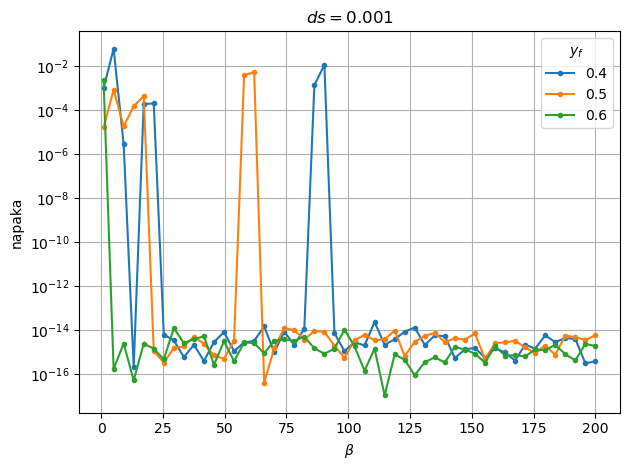

In [ ]:
for i in range(len(napaka)):
    plt.plot(beta_list, np.abs(napaka[i]), '.-', label=f'{lege[i]:.1f}')
plt.title(f'$ds=${ds}')
plt.grid()
plt.legend(title='$y_f$')
plt.xlabel('$\\beta$')
plt.ylabel('napaka')
plt.yscale('log')
plt.tight_layout()
#plt.savefig('./slike/napaka_rp.pdf')

In [ ]:
# napaka dolžine
x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.5 #RP lega končnega vpetja
ds = 0.002
L=1 #dolžina vrvi
s=np.arange(0., L, ds)
alpha0 = np.pi/4 #ZP
F0= 1 #ZP

beta_list = np.linspace(1, 200, 50)
lege = np.arange(0.4, 0.61, 0.1)
napaka_L = []
for y_f in lege:
    nap = []
    alpha0, F0 = np.pi/4, 0.1
    for beta in beta_list:
        y, (alpha0,F0) = vrv_min(beta, alpha0, F0) #uporaba predhodnjih ZP
        err = np.abs(1 - np.sum(np.sqrt(np.diff(y[0])**2 + np.diff(y[1])**2)))
        nap.append(err)
    napaka_L.append(nap)
napaka_L = np.array(napaka_L)

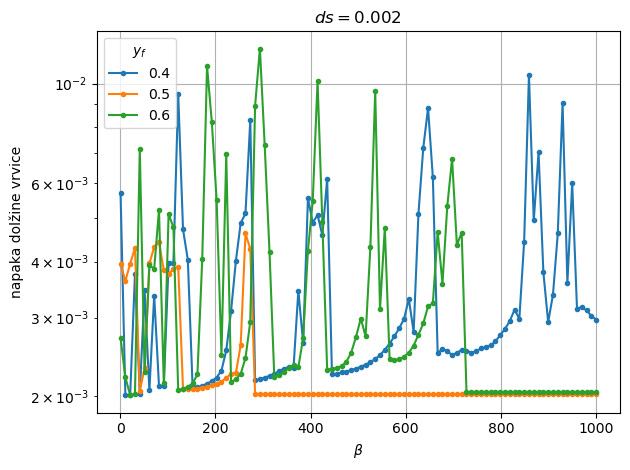

In [ ]:
for i in range(len(napaka_L)):
    plt.plot(beta_list, np.abs(napaka_L[i]), '.-', label=f'{lege[i]:.1f}')
plt.title(f'$ds=${ds}')
plt.legend(title='$y_f$')
plt.grid()
plt.xlabel('$\\beta$')
plt.ylabel('napaka dolžine vrvice')
plt.yscale('log')
plt.tight_layout()
#plt.savefig('./slike/napaka_dolzine.pdf')

## 2D plot

In [49]:
beta  = 100 #parameter
F_max = 20
n_F = 100
n_phi = 100
kot =np.linspace(0, np.pi/2+0.05, n_phi)
sila =np.linspace(0.1, F_max, n_F)
# okoli najdenega min
# d_phi = np.pi/10
# d_F = 0.4
# kot =np.linspace(alpha0-d_phi, alpha0+d_phi, n_phi)
# sila =np.linspace(F0-d_F, F0+d_F, n_F)
print(f'$\\alpha_0=${alpha0}, $F_0=${F0}')

x0,y0 = 0.,0. #ZP zač. vpetje
x_f,y_f = 0., 0.5 #RP lega končnega vpetja
ds = 0.001
L=1 #dolžina vrvi
s=np.arange(0., L, ds)

napaka = []
i=0
err=0
n_iter = n_F*n_phi
for alpha_0 in kot:
    print(f'{i}/{n_iter}, napaka: {np.sum(err):.0e}', end='\r')
    nap=[]
    for F_0 in sila:
        i+=1
        y_zp=np.array([alpha_0,F_0])
        #res = optimize.root(napaka_vrv, x0=y_zp, tol=10**(-6))
        #err = napaka_vrv(res.x) #iskanje min!!!
        err = napaka_vrv(y_zp) #grid search!
        nap.append(np.sum(err))
    napaka.append(nap)
print(f'{i}/{n_iter}, napaka: {np.sum(err):.0e}', end='\r')
napaka = np.array(napaka)

$\alpha_0=$-9.894020687613637, $F_0=$0.31051547386716816


(-9.894020687613637, 0.31051547386716816)

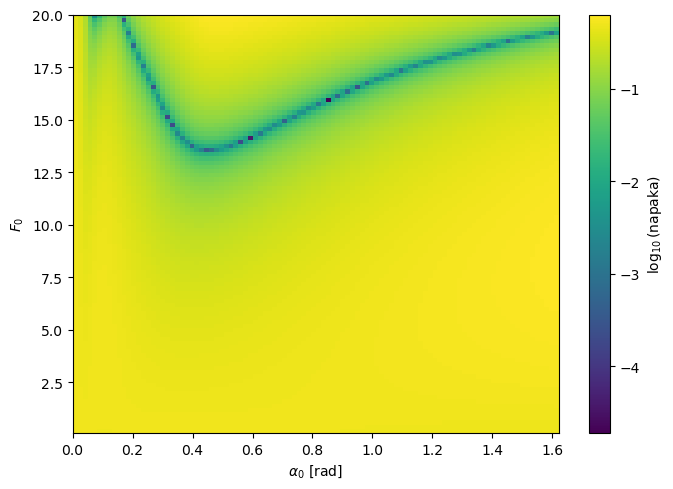

In [51]:
fig, ax = plt.subplots(figsize=(7,5))
im = ax.imshow(np.log10(abs(napaka)), extent=[kot[0], kot[-1], sila[0], sila[-1]])
cbar = fig.colorbar(im)
cbar.set_label('$\\log_{10}$(napaka)')
ax.set_aspect('auto')
#plt.plot(alpha0, F0, 'r.')
ax.axis('on')

# y_ticks = [sila[0],sila[len(sila)//2], sila[-1]] #sila[::len(sila)//2]
# y_labels = [f"{i:.2f}" for i in y_ticks]
# ax.set_yticks(np.linspace(0, len(sila)-1, len(y_ticks)))
# ax.set_yticklabels(y_labels)

# x_ticks = [kot[0],kot[len(sila)//2], kot[-1]] #kot[::len(kot)//2]
# x_labels = [f"${{{int(i*4/(np.pi))}}}\, \pi/4$" for i in x_ticks]
# #x_labels = [f"${{{i:.4f}}}\,\pi$" for i in x_ticks]
# ax.set_xticklabels(x_labels)
# ax.set_xticks(np.linspace(0, len(kot)-1, len(x_ticks)))

plt.xlabel('$\\alpha_0$ [rad]')
plt.ylabel('$F_0$')
plt.tight_layout()
#plt.savefig('./slike/2d_napaka_ZP_optimize_yf_0.5.pdf')
#plt.savefig('./slike/2d_napaka_ZP_yf_0.5.pdf')
alpha0, F0